### DAT Load & Initial Inspection


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the Raw data for  Cleaning
df = pd.read_excel('Ecommerce_Data.xlsx', sheet_name='Raw_Messy_Data')

# Printing Data Shape , data types,and missing values.
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print("\nMissing Values Count:")
print(df.isnull().sum())

# Review sample rows
df.head(10)

(1000, 10)
Transaction_ID     object
Customer_Name      object
Customer_Email     object
Age               float64
City               object
Category           object
Price             float64
Quantity          float64
Order_Date         object
Payment_Method     object
dtype: object
Transaction_ID      0
Customer_Name     154
Customer_Email    163
Age                77
City              118
Category          143
Price             129
Quantity          132
Order_Date        160
Payment_Method    167
dtype: int64

Missing Values Count:
Transaction_ID      0
Customer_Name     154
Customer_Email    163
Age                77
City              118
Category          143
Price             129
Quantity          132
Order_Date        160
Payment_Method    167
dtype: int64


,Transaction_ID,Customer_Name,Customer_Email,Age,City,Category,Price,Quantity,Order_Date,Payment_Method
0,TXN-999,NaN,NaN,150.0,delhi,elec,99999.0,NaN,2025-01-15,COD
1,TXN-1001,Rahul Sharma,NaN,999.0,MUMBAI,ELECTRONICS,-200.0,3.0,2025/03/10,NaN
2,TXN-1002,Rahul Sharma,INVALID_EMAIL,150.0,bengaluru,Books,1500.0,1.0,15/02/2025,upi
3,TXN-1003,NaN,INVALID_EMAIL,35.0,MUMBAI,ELECTRONICS,NaN,2.0,15/02/2025,upi
4,TXN-1004,ANIT KUMAR,INVALID_EMAIL,29.0,Mumbai,Books,NaN,-1.0,2025/03/10,Credit Card
5,TXN-1005,Priya Singh,neha.v@gmail.com,28.0,Delhi,NaN,150.0,1.0,2025-01-15,upi
6,TXN-1006,Priya Singh,NaN,29.0,Delhi,Clothing,-200.0,1.0,2025-01-15,COD
7,TXN-1007,Priya Singh,amit@domain,29.0,Bengaluru,elec,1500.0,5.0,NaN,UPI
8,TXN-1008,NaN,amit@domain,999.0,NaN,ELECTRONICS,NaN,2.0,NaN,NaN
9,TXN-1009,Rahul Sharma,priya.s@yahoo.com,-5.0,bengaluru,Books,1500.0,-1.0,NaN,Cash on Delivery


##Data Cleaning (Step-by-Step Fixes)
1.Droping duplicate transaction
2.Standarize Text Columns(Whitespace & Casing)
3.Handling the Invalid Email Addresses
4.Filtering the Outliners and Impossible
5.Standarize Date Column
6.Adding the Total Revenue Feature

##1.Droping duplicate transaction

In [11]:
# Counting the Duplicate transactions
print('Duplicates count:', df.duplicated(subset=['Transaction_ID']).sum())

Duplicates count: 83


In [13]:
# Now Drop the Duplicates
df = df.drop_duplicates(subset=['Transaction_ID'],keep='first')
# Check count of remaining duplicates
remaining_duplicates = df.duplicated(subset=['Transaction_ID']).sum()
print("Remaining Duplicates:", remaining_duplicates)

Remaining Duplicates: 0


##2.Standarize Text Columns(Whitespace & Casing)

In [17]:
# Whitespace strip and Title case apply
df['Customer_Name'] = df['Customer_Name'].astype(str).str.strip().str.title()
df['City'] = df['City'].astype(str).str.strip().str.title()
# Converting 'nan' into proper NaN
df['City'] = df['City'].replace({'Nan': np.nan})
# Category values standardize karein
df['Category'] = df['Category'].astype(str).str.strip().str.title()
df['Category'] = df['Category'].replace({'Elec': 'Electronics', 'Electronics': 'Electronics', 'Nan': np.nan})

In [18]:
# City Value check
print("City Frequency:")
print(df['City'].value_counts())

City Frequency:
City
Mumbai       235
Bengaluru    227
Delhi        222
Kolkata      121
Name: count, dtype: int64


##3.Handling the Invalid Email Addresses





In [20]:
# Replacing Invalid string emails
df['Customer_Email'] = df['Customer_Email'].replace(['INVALID_EMAIL', 'nan'], np.nan)
# Valid email pattern (basic check)
valid_email_regex = r'^[\w\.-]+@[\w\.-]+\.\w+$'
df['Customer_Email'] = df['Customer_Email'].where(df['Customer_Email'].str.match(valid_email_regex, na=False), np.nan)

In [22]:
# Print the cleaned 'Customer_Email' series directly
print(df['Customer_Email'])
print(df['Customer_Email'].value_counts())

0                   NaN
1                   NaN
2                   NaN
3                   NaN
4                   NaN
             ...       
994                 NaN
995    neha.v@gmail.com
997    neha.v@gmail.com
998    neha.v@gmail.com
999                 NaN
Name: Customer_Email, Length: 917, dtype: object
Customer_Email
neha.v@gmail.com     163
rahul@gmail.com      149
priya.s@yahoo.com    136
Name: count, dtype: int64


###4. Filtering Outliers and Impossible Values

In [24]:
# Age realistic range (18 to 80 years) set
df['Age'] = df['Age'].apply(lambda x: x if 18 <= x <= 80 else np.nan)

# Price realistic range (> 0 aur < 50000) filter
df['Price'] = df['Price'].apply(lambda x: x if 0 < x < 50000 else np.nan)

# Quantity validation (> 0)
df['Quantity'] = df['Quantity'].apply(lambda x: x if x > 0 else np.nan)

In [29]:
print(df['Age'])
print(df['Price'])
print(df['Quantity'])

0       NaN
1       NaN
2       NaN
3      35.0
4      29.0
       ... 
994     NaN
995     NaN
997    35.0
998     NaN
999     NaN
Name: Age, Length: 917, dtype: float64
0         NaN
1         NaN
2      1500.0
3         NaN
4         NaN
        ...  
994     350.0
995       NaN
997       NaN
998     150.0
999    1200.5
Name: Price, Length: 917, dtype: float64
0      NaN
1      3.0
2      1.0
3      2.0
4      NaN
      ... 
994    3.0
995    NaN
997    NaN
998    NaN
999    5.0
Name: Quantity, Length: 917, dtype: float64


##5.Standarize Date Column

In [28]:
# Date parse
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='mixed', errors='coerce')

# Extracting month and year
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_Year'] = df['Order_Date'].dt.year


In [30]:
print(df['Order_Date'])
print(df['Order_Month'])
print(df['Order_Year'])

0     2025-01-15
1     2025-03-10
2     2025-02-15
3     2025-02-15
4     2025-03-10
         ...    
994   2025-03-10
995   2025-02-15
997          NaT
998   2025-04-20
999   2025-01-15
Name: Order_Date, Length: 917, dtype: datetime64[ns]
0      1.0
1      3.0
2      2.0
3      2.0
4      3.0
      ... 
994    3.0
995    2.0
997    NaN
998    4.0
999    1.0
Name: Order_Month, Length: 917, dtype: float64
0      2025.0
1      2025.0
2      2025.0
3      2025.0
4      2025.0
        ...  
994    2025.0
995    2025.0
997       NaN
998    2025.0
999    2025.0
Name: Order_Year, Length: 917, dtype: float64


##6.Adding the Total Revenue Feature

In [32]:
df["Total_Amount"] = df['Price'] * df['Quantity']

In [34]:
# Print the newly created 'Total_Amount' column
print(df['Total_Amount'])

0         NaN
1         NaN
2      1500.0
3         NaN
4         NaN
        ...  
994    1050.0
995       NaN
997       NaN
998       NaN
999    6002.5
Name: Total_Amount, Length: 917, dtype: float64


## Exploratory Data Analysis (EDA & Insights)

         Category  Total_Amount
0           Books       90755.5
1        Clothing      118043.5
2     Electronics      298691.5
3  Home & Kitchen       91640.0
City
Mumbai       235
Bengaluru    227
Delhi        222
Kolkata      121
Name: count, dtype: int64


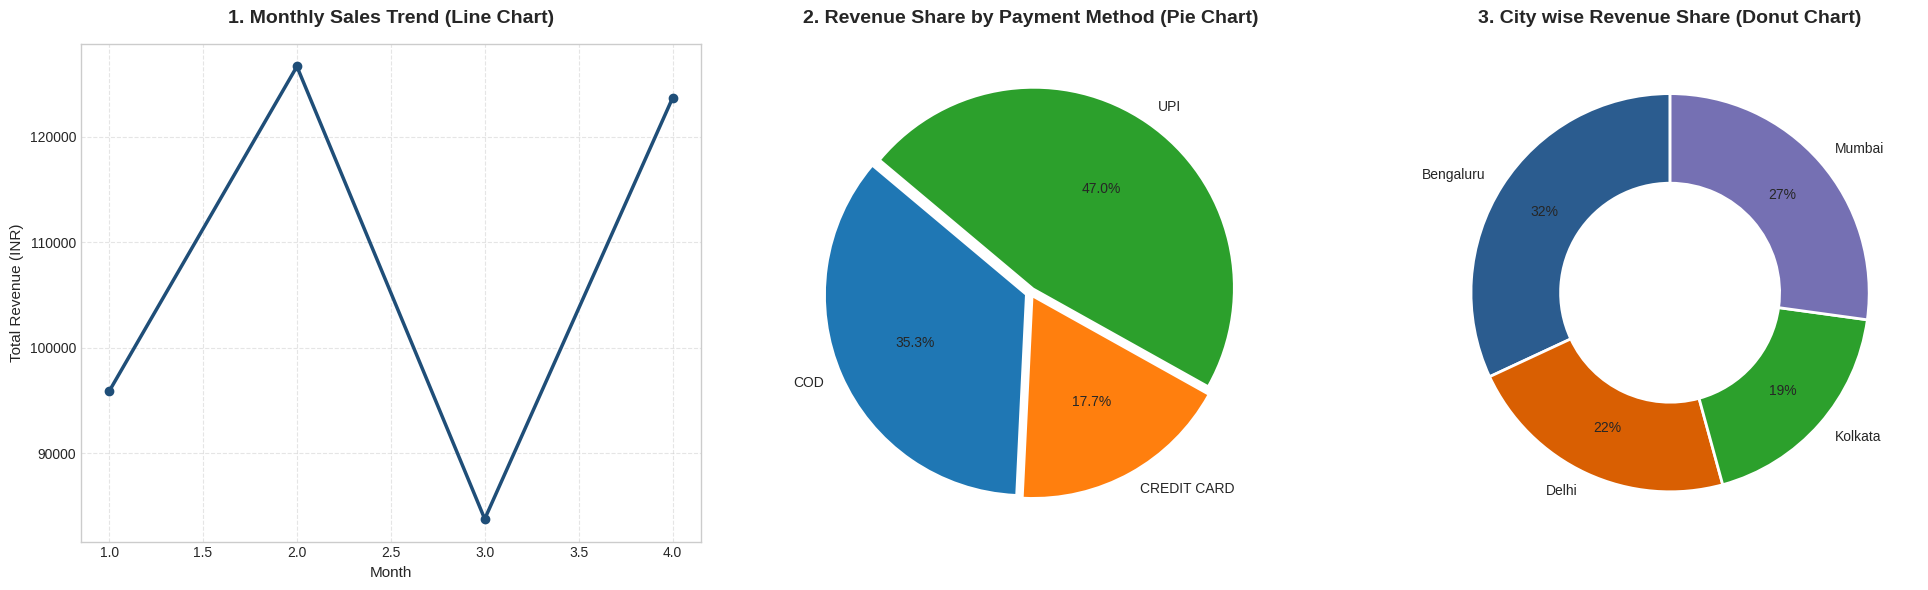

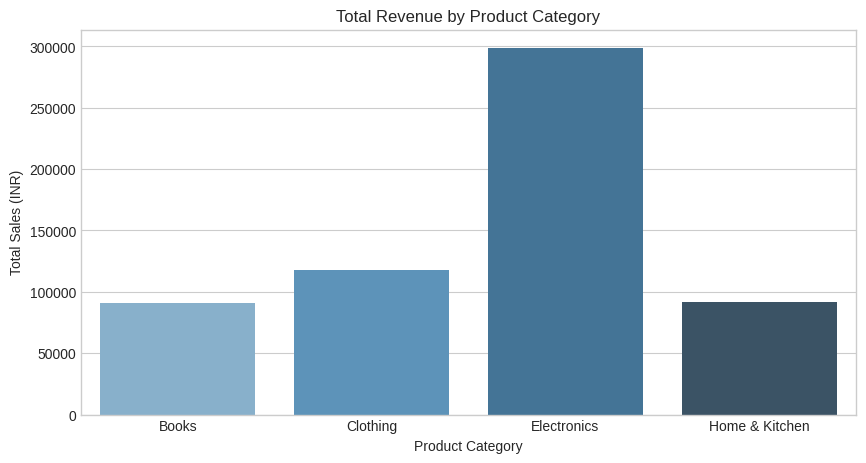

In [47]:
# 1. Category wise Total Revenue
category_revenue = df.groupby('Category')['Total_Amount'].sum().reset_index()
print(category_revenue)

# 2. Top Cities by Orders
city_orders = df['City'].value_counts()
print(city_orders)

# Set Theme
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# ----------------------------------------------------
# CHART 1: LINE CHART (Monthly Revenue Trend)
# ----------------------------------------------------
monthly_sales = df.groupby('Order_Month', observed=False)['Total_Amount'].sum().reset_index()
axes[0].plot(monthly_sales['Order_Month'], monthly_sales['Total_Amount'], marker='o', color='#1F4E78', linewidth=2.5, label='Total Revenue')
axes[0].set_title('1. Monthly Sales Trend (Line Chart)', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Month', fontsize=11)
axes[0].set_ylabel('Total Revenue (INR)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

# ----------------------------------------------------
# CHART 2: PIE CHART (Payment Method Revenue Share)
# ----------------------------------------------------
payment_sales = df.groupby('Payment_Method')['Total_Amount'].sum()
colors_pie = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

axes[1].pie(
    payment_sales,
    labels=payment_sales.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_pie[:len(payment_sales)],
    explode=[0.03] * len(payment_sales)
)
axes[1].set_title('2. Revenue Share by Payment Method (Pie Chart)', fontsize=14, fontweight='bold', pad=15)

# ----------------------------------------------------
# CHART 3: DONUT CHART (City / Region wise Comparison)
# ----------------------------------------------------
city_sales = df.groupby('City')['Total_Amount'].sum()
colors_donut = ['#2b5c8f', '#d95f02', '#2ca02c', '#7570b3', '#e7298a']

axes[2].pie(
    city_sales,
    labels=city_sales.index,
    autopct='%1.0f%%',
    startangle=90,
    colors=colors_donut,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
axes[2].set_title('3. City wise Revenue Share (Donut Chart)', fontsize=14, fontweight='bold', pad=15)

# Tight Layout & Display
plt.tight_layout()
plt.show()

# Visualizations (Charts) - Fixed warning by adding hue='Category' and legend=False
plt.figure(figsize=(10, 5))
sns.barplot(data=category_revenue, x='Category', y='Total_Amount', hue='Category', palette='Blues_d', legend=False)
plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (INR)')
plt.show()

## Export Clean Data

In [48]:
df.to_csv('Cleaned_Ecommerce_Data.csv', index=False)
print("Cleaned file successfully exported as csv")

Cleaned file successfully exported as csv


In [53]:
from google.colab import files

print("Data successfully cleaned! Downloading CSV file...")
# Use the CSV filename exported in the previous cell
files.download('Cleaned_Ecommerce_Data.csv')

Data successfully cleaned! Downloading CSV file...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>